### Домашнє завдання: Кластеризація в Аналізі Персоналій Клієнтів

#### Контекст
В цьому ДЗ ми скористаємось алгоритмами кластеризації для задачі аналізу портретів клієнтів (Customer Personality Analysis).

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Завдання
На основі наданих даних в файлі `marketing_campaign.csv` потрібно виконати кластеризацію, щоб виявити сегменти клієнтів.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


**Завдання 1**. Завантажте дані з `marketing_campaign.csv` в Pandas dataframe і виведіть основну інформацію про дані: скільки всього рядків і колонок, які типи даних мають колонки, скільки пропущених значень.

In [406]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
import plotly.express as px
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 150)

In [407]:
df = pd.read_csv('../data/marketing_campaign.csv', sep='\t')
display(df.head(6))
print(df.shape)
display(df.info())
display(df.isnull().sum())

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0
5,7446,1967,Master,Together,62513.0,0,1,09-09-2013,16,520,42,98,0,42,14,2,6,4,10,6,0,0,0,0,0,0,3,11,0


(2240, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 n

None

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

**Завдання 2.** Заповніть пропущені значення з врахуванням того завдання (кластеризація), яке ми виконуємо. Поясніть свій вибір заповнення пропущених значень.

In [408]:
round(df.Income.describe(percentiles = [0.75,0.99]))

count      2216.0
mean      52247.0
std       25173.0
min        1730.0
50%       51382.0
75%       68522.0
99%       94459.0
max      666666.0
Name: Income, dtype: float64

In [409]:
df.Income.value_counts(bins=10).sort_index()

(1065.063, 68223.6]     1654
(68223.6, 134717.2]      554
(134717.2, 201210.8]       7
(201210.8, 267704.4]       0
(267704.4, 334198.0]       0
(334198.0, 400691.6]       0
(400691.6, 467185.2]       0
(467185.2, 533678.8]       0
(533678.8, 600172.4]       0
(600172.4, 666666.0]       1
Name: count, dtype: int64

In [410]:
import warnings

def dist_box(dataset, column):
    with warnings.catch_warnings():
      warnings.simplefilter("ignore")

      plt.figure(figsize=(16,6))

      plt.subplot(1,2,1)
      sns.distplot(dataset[column], color = 'purple')
      pltname = 'Графік розподілу для ' + column
      plt.ticklabel_format(style='plain', axis='x')
      plt.title(pltname)

      plt.subplot(1,2,2)
      red_diamond = dict(markerfacecolor='r', marker='D')
      sns.boxplot(y = column, data = dataset, flierprops = red_diamond)
      pltname = 'Боксплот для ' + column
      plt.title(pltname)

      plt.show()

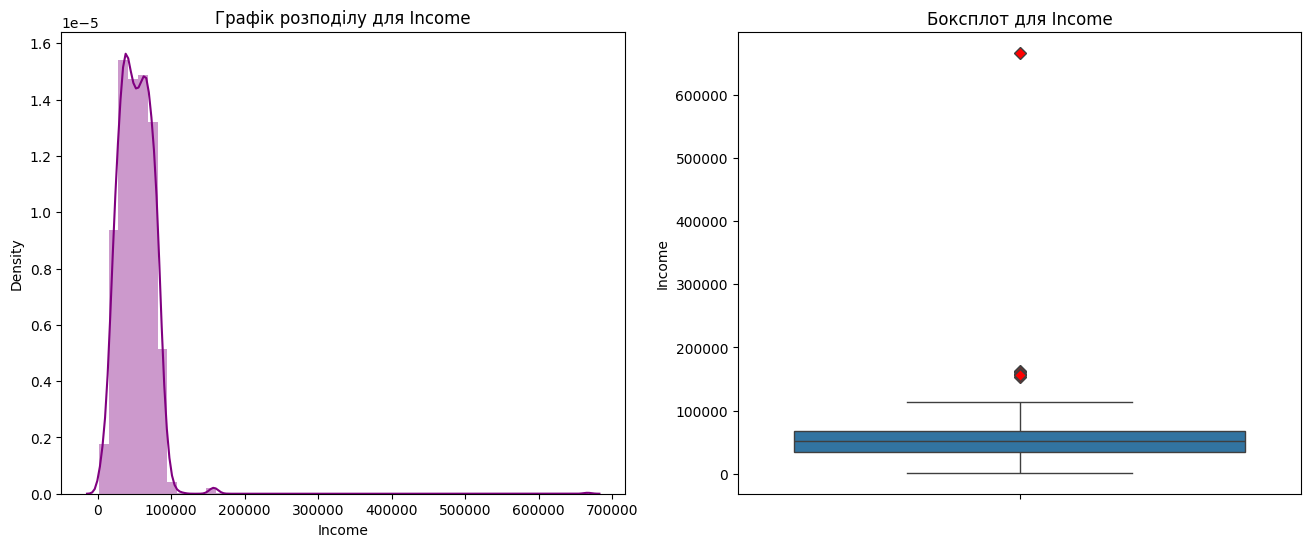

In [411]:
dist_box(df,'Income')

Дуже пикові графіки, явно є викід. Побудуємо графіки з доходом < max

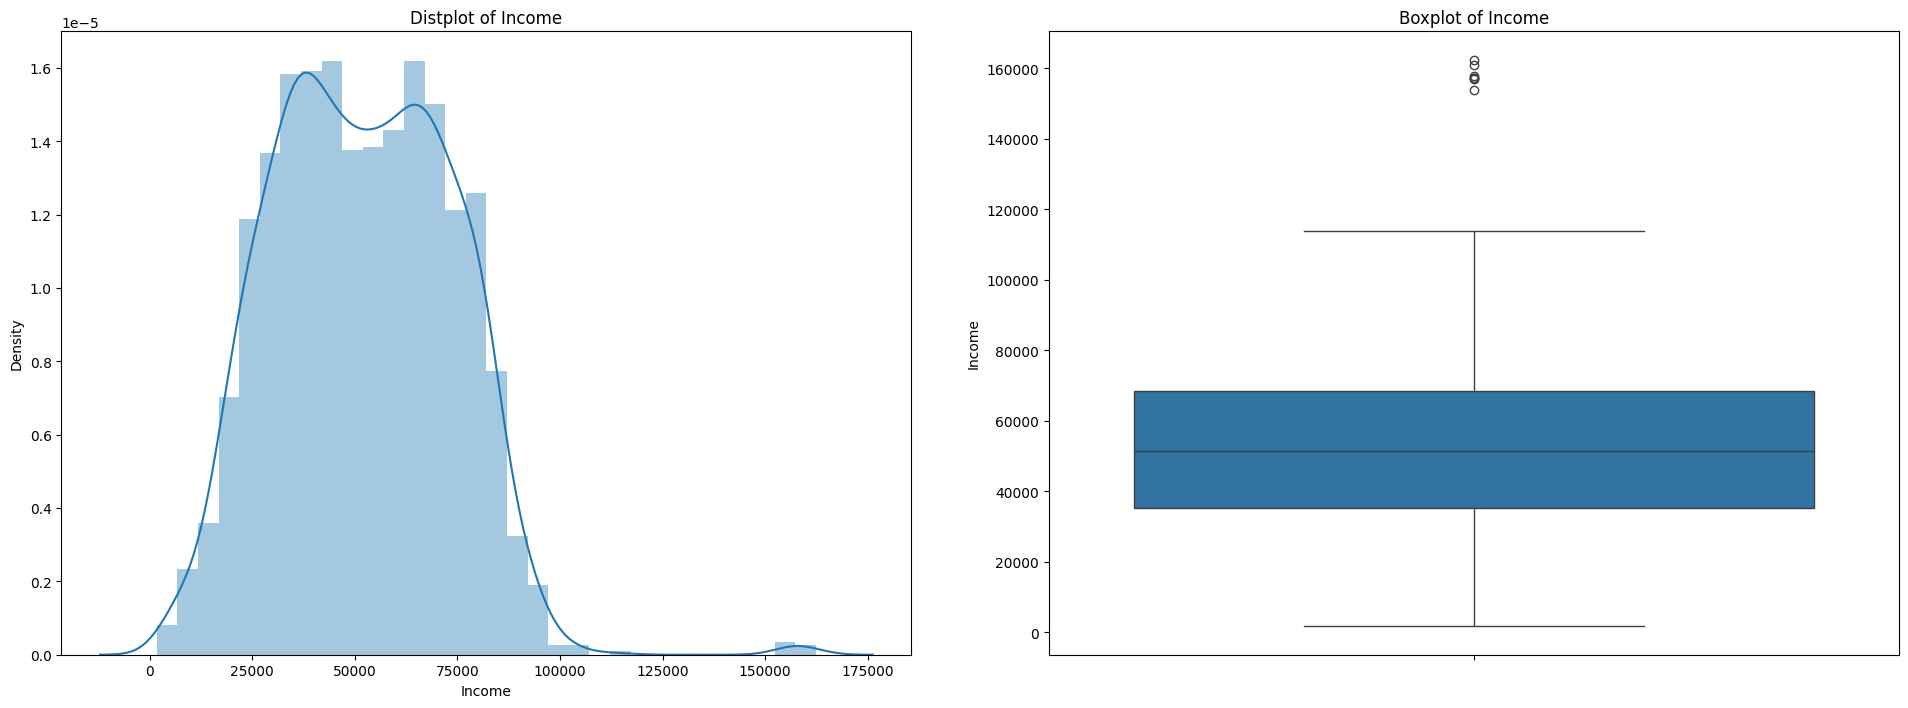

In [412]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    plt.subplots(1,2 ,figsize = (20,8))

    plt.subplot(121)
    sns.distplot(df[df.Income < df.Income.max()].Income)
    pltname = 'Distplot of ' + 'Income'
    plt.title(pltname)

    plt.subplot(122)
    sns.boxplot(df[df.Income < df.Income.max()].Income)
    pltname = 'Boxplot of ' + 'Income'
    plt.title(pltname)

    plt.tight_layout(pad = 4)

In [413]:
df[df.Income == df.Income.max()]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
2233,9432,1977,Graduation,Together,666666.0,1,0,02-06-2013,23,9,14,18,8,1,12,4,3,1,3,6,0,0,0,0,0,0,3,11,0


In [414]:
print(df[df.Income < df.Income.max()].Income.mode()[0])
print(round(df[df.Income < df.Income.max()].Income.mean()))
print(round(df[df.Income < df.Income.max()].Income.median()))

7500.0
51970
51373


In [415]:
df = df[df.Income != df.Income.max()]
df.shape

(2239, 29)

In [416]:
# Зробимо разбивку на біни після видалення викиду
df.Income.value_counts(bins=10).sort_index()


(1569.332, 17796.7]      90
(17796.7, 33863.4]      410
(33863.4, 49930.1]      558
(49930.1, 65996.8]      528
(65996.8, 82063.5]      472
(82063.5, 98130.2]      143
(98130.2, 114196.9]       7
(114196.9, 130263.6]      0
(130263.6, 146330.3]      0
(146330.3, 162397.0]      7
Name: count, dtype: int64

In [417]:
# Відсоток незаповненних значень
round(df.Income.isnull().sum() / df.Income.count() * 100)

1

**Спостереження**
- Пропущені значення є тільки в категорії Income
. Min значення 1730, 99 персентіль -  94478, а max - 666666. Є один помітний викід
- Аналізуємо цей викид із доходом 666666 - нереальні значення в інших характеристіках, краще буде його прибрати
- Найчастіше повторюване значення - 7500, середнє - 51970, медіана - 51373. Дивлячись на новий розподіл, бачимо два піки на вершині дзвоника, там знаходяться і середнє, і медіана. Але з урахуванням того, що є група точок, яка також розташована сильно правіше, що впливає на середнє значення, краще заповнити пропуски медіаною 


In [418]:
df.Income.fillna(df.Income.median(), inplace=True)
df.Income.isnull().sum()

C:\Users\PC\AppData\Local\Temp\ipykernel_7516\1816896746.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





np.int64(0)

**Завдання 3.** У нас є декілька колонок з категоріальними значеннями та одна колонка з датою. Як би ви обробили ці колонки для того, аби передати їх в алгоритм кластеризації?

Реалізуйте обробку категоріальних колонок і колонки з датою та перетворіть їх на ознаки, корисні для кластеризації з вашого погляду.

In [419]:
df.select_dtypes(include='object').columns

Index(['Education', 'Marital_Status', 'Dt_Customer'], dtype='object')

In [420]:
df.Education.value_counts()

Education
Graduation    1126
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [421]:
freq = df.Marital_Status.value_counts(normalize=True)
print(round(freq, 4))

Marital_Status
Married     0.3859
Together    0.2586
Single      0.2144
Divorced    0.1036
Widow       0.0344
Alone       0.0013
Absurd      0.0009
YOLO        0.0009
Name: proportion, dtype: float64


In [422]:
# Є значення, кількість яких меньш ніж 0,5%, тому сгрупуємо їх до одного значення Other
df['Marital_Status_N'] = df.Marital_Status.apply(lambda x: x if freq[x] >= 0.005 else 'Other')
print(df.Marital_Status_N.value_counts(normalize=True))

Marital_Status_N
Married     0.385887
Together    0.258598
Single      0.214381
Divorced    0.103618
Widow       0.034390
Other       0.003126
Name: proportion, dtype: float64


In [423]:
from sklearn import preprocessing
enc = preprocessing.OneHotEncoder()
enc.fit(df[['Education', 'Marital_Status_N']])
enc.categories_

[array(['2n Cycle', 'Basic', 'Graduation', 'Master', 'PhD'], dtype=object),
 array(['Divorced', 'Married', 'Other', 'Single', 'Together', 'Widow'],
       dtype=object)]

In [424]:
one_hot = enc.transform(df[['Education', 'Marital_Status_N']]).toarray()
one_hot
df[enc.categories_[0]] = one_hot[:,:5]
df[enc.categories_[1]] = one_hot[:,5:]

In [425]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Marital_Status_N,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,Single,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,Single,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,Together,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,Together,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,Married,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [426]:
# З дати можно зробити числову колонку з даними віку людини
df.Dt_Customer = pd.to_datetime(df.Dt_Customer, format="%d-%m-%Y")
df["Days_As_Customer"] = (pd.Timestamp.today() - df.Dt_Customer).dt.days
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Marital_Status_N,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,Single,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,Single,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,Together,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4799
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,Together,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4626
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,Married,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4648


**Завдання 4**.
1. Запишіть в змінну X ті дані, які будете кластеризувати.
2. Побудуйте кластеризацію з KMeans на 3 кластери.
3. Обчисліть метрику силуету для цієї кластеризації.

In [427]:
X = df.select_dtypes(include='number')
X.head()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,5524,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150
1,2174,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600
2,4141,1965,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4799
3,6182,1984,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4626
4,5324,1981,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4648


In [428]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init='auto')
kmeans.fit(X)

labels = kmeans.predict(X)
print(labels)

[0 0 2 ... 0 2 0]


In [429]:
centroids = kmeans.cluster_centers_
s = metrics.silhouette_score(X, labels, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.49


**Завдання 5.** Візуалізуйте знайдені кластери разом з наявними даними та проаналізуйте кластери. У нас ознак більше, ніж 2 або 3, тож, тут треба подумати, які саме ознаки варто використати для візуалізації аби вони були інформативними. Рекомендую точно звернути увагу на харакетиристики про дохід користувачів і те, як вони взаємодять з магазинок (кількість покупок і тд).

Для візуалізації зручно може бути використати `plotly.express.scatter_3d` для 3D графіку розсіювання, але тут можна скористатись будь-яким зрозумілим і зручним для вас методом візуалізації. Опишіть свої спостереження, чи кластери мають сенс?

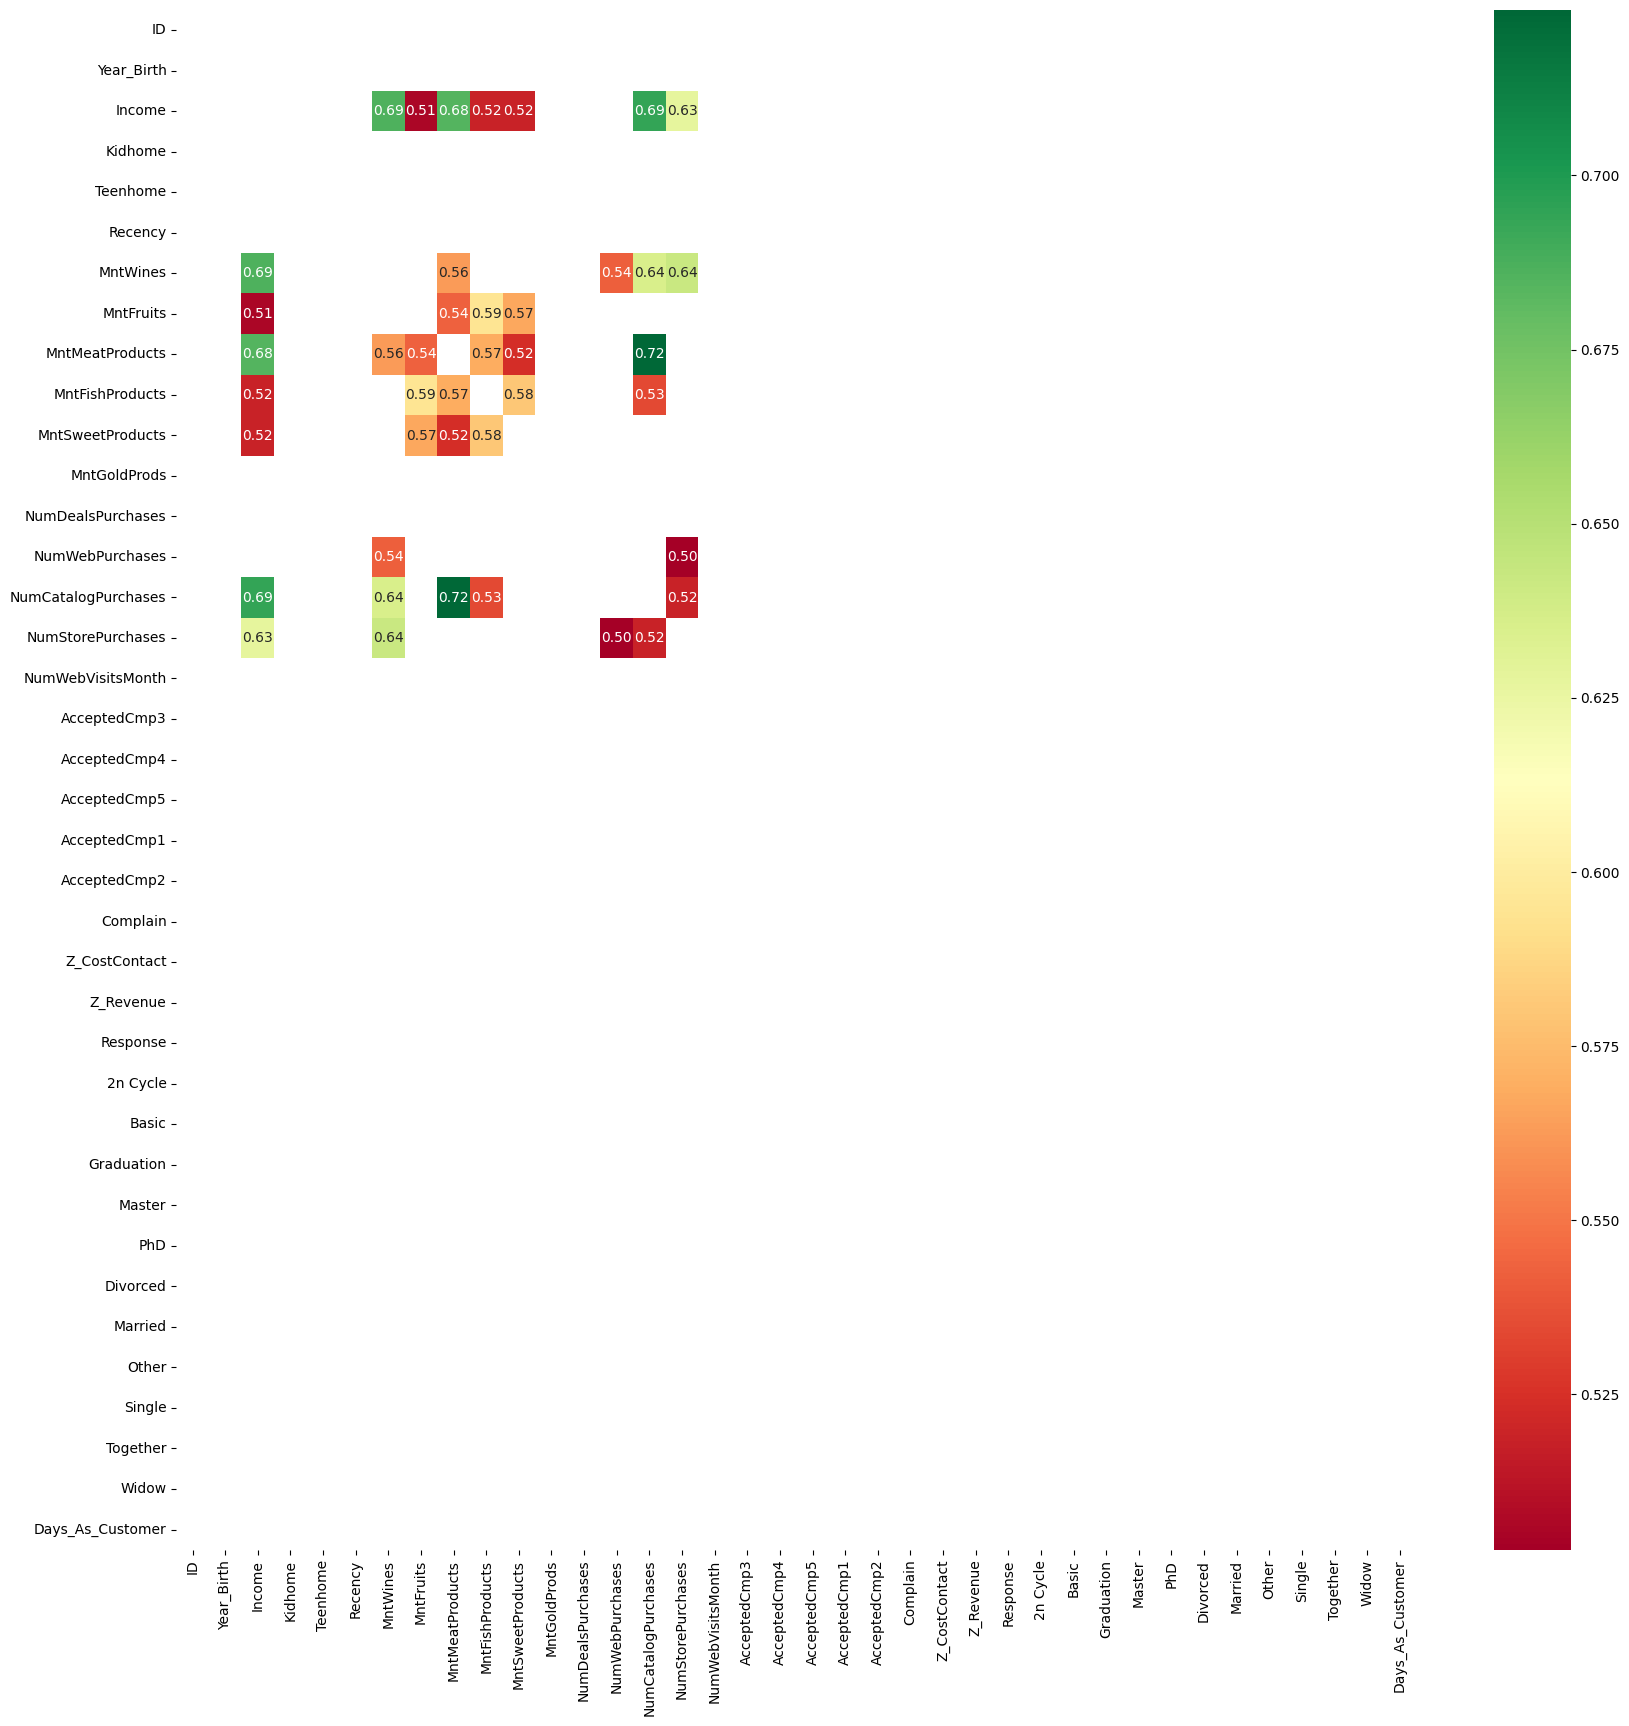

In [430]:
corr_X = X.corr()
plt.figure(figsize = (20,20))
sns.heatmap(data = corr_X[(corr_X >= 0.5) & (corr_X < 0.9999)], annot = True, cmap = "RdYlGn", cbar = True, fmt='.2f')
plt.show()

In [431]:
corr_X[corr_X <= 0.99].unstack().sort_values(ascending = False).head(20)

NumCatalogPurchases  MntMeatProducts        0.723782
MntMeatProducts      NumCatalogPurchases    0.723782
Income               NumCatalogPurchases    0.693740
NumCatalogPurchases  Income                 0.693740
MntWines             Income                 0.686147
Income               MntWines               0.686147
                     MntMeatProducts        0.684375
MntMeatProducts      Income                 0.684375
NumStorePurchases    MntWines               0.641980
MntWines             NumStorePurchases      0.641980
NumCatalogPurchases  MntWines               0.635158
MntWines             NumCatalogPurchases    0.635158
NumStorePurchases    Income                 0.627063
Income               NumStorePurchases      0.627063
MntFishProducts      MntFruits              0.594780
MntFruits            MntFishProducts        0.594780
MntSweetProducts     MntFishProducts        0.579807
MntFishProducts      MntSweetProducts       0.579807
MntMeatProducts      MntFishProducts        0.

Пари повторюються, обираємо найбільш корелюючи ознаки
**Income, NumCatalogPurchases, MntMeatProducts**


In [432]:
X['Cluster'] = labels
fig = px.scatter_3d(X,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="Cluster",
                    hover_data=["Cluster"],
                    title='3d візуалізація: Дохід, Покупки за каталогом, М_ясні продукти'
)
fig.show()


**Спостереження**\
Кластери чудово розділені. Нізкий доход - невелика кількість покупок за каталогом, невелика кількість м'ясних продуктів. Покупці з середнім доходом  - в 2 рази зростають покупки за каталогом, м'яснітеж рази в 2-2,5. Значний дохід - каталог як і на середнем рівні доходу, а вот покупка м'ясних продуктів значно збільшується. На верхньому шарі графіку є викиди.

**Завдання 6**. Масштабуйте дані (StandardScaler/MinMaxScaler) і побудуйте знову кластеризацію KMeans на 3 кластери і обчисліть метрику силуету. Опишіть порівняння з експериментом без масштабування значень.

In [433]:

from sklearn.preprocessing import MinMaxScaler, StandardScaler
# Масштабуємо
scaler = MinMaxScaler()
X_minmax = X.copy()
#features = ['Income', 'NumCatalogPurchases', 'MntMeatProducts']
X_minmax = X_minmax.drop(columns = ['Cluster'])
display(X_minmax.head(2))

X_minmax = pd.DataFrame(scaler.fit_transform(X_minmax))
X_minmax.columns = X.columns[:-1]
X_minmax.head(2)


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,5524,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150
1,2174,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,0.493611,0.621359,0.351086,0.0,0.0,0.585859,0.425318,0.442211,0.316522,0.664093,0.334601,0.243094,0.200000,0.296296,0.357143,0.307692,0.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.948498
1,0.194263,0.592233,0.277680,0.5,0.5,0.383838,0.007368,0.005025,0.003478,0.007722,0.003802,0.016575,0.133333,0.037037,0.035714,0.153846,0.25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.161660


In [434]:
# Навчаємо K-means на нармалізованих даних
kmeans = KMeans(n_clusters=3, n_init='auto')
kmeans.fit(X_minmax)
labels_minmax = kmeans.predict(X_minmax)
X_minmax['Cluster'] = labels_minmax
fig = px.scatter_3d(X_minmax,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="Cluster",
                    title='3d візуалізація: MinMaxScaler'
)
fig.show()

In [435]:
centroids_minmax = kmeans.cluster_centers_
s_minmax = metrics.silhouette_score(X_minmax, labels_minmax, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s_minmax:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.24


In [436]:
# Стандартізуємо
scaler_standart = StandardScaler()
X_standart = X.copy()
X_standart = X_standart.drop(columns = ['Cluster'])
display(X_standart.head(2))

X_standart = pd.DataFrame(scaler.fit_transform(X_standart))
X_standart.columns = X.columns[:-1]
X_standart.head(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,5524,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150
1,2174,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer
0,0.493611,0.621359,0.351086,0.0,0.0,0.585859,0.425318,0.442211,0.316522,0.664093,0.334601,0.243094,0.200000,0.296296,0.357143,0.307692,0.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.948498
1,0.194263,0.592233,0.277680,0.5,0.5,0.383838,0.007368,0.005025,0.003478,0.007722,0.003802,0.016575,0.133333,0.037037,0.035714,0.153846,0.25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.161660


In [437]:
# Навчаємо K-means на стандартізованих даних
kmeans = KMeans(n_clusters=3, n_init='auto')
kmeans.fit(X_standart)
labels_standart = kmeans.predict(X_standart)
X_standart['Cluster'] = labels_standart
fig = px.scatter_3d(X_standart,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="Cluster",
                    title='3d візуалізація: StandardScaler'
)
fig.show()

In [438]:
centroids_standart = kmeans.cluster_centers_
s_standart = metrics.silhouette_score(X_standart, labels_standart, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s_standart:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.23


**Спостереження**

Метод K-Means без нормалізації та стандартизації показав кращі результати, відповідно до метрики силуету – 0.49 проти 0.21 та 0.24. Метод ділить на класи, орієнтуючись на різницю між екземплярами. Коли ми робимо більш рівними значення ознак, то знаходити розбіжності стає важче.

**Завдання 7.** З візуалізацій на попередньому кроці ви могли побачити якісь викиди в даних. Опрацюйте викиди (можна видалити ці рядки або придумати інший спосіб).

In [439]:
# Обчислення мінімального та максимального діапазону відхилень для числових стовпців
def outlier_range(dataset,column):
    Q1 = dataset[column].quantile(0.25)
    Q3 = dataset[column].quantile(0.75)
    IQR = Q3 - Q1
    Min_value = (Q1 - 1.5 * IQR)
    Max_value = (Q3 + 1.5 * IQR)
    return Max_value

In [440]:
Max_value_Income = outlier_range(X, 'Income')
print(Max_value_Income)
X[X['Income'] > Max_value_Income]
#Income, NumCatalogPurchases, MntMeatProducts (MntWines)

117393.5


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer,Cluster
164,8475,1973,157243.0,0,1,98,20,2,1582,1,2,1,15,0,22,0,0,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4607,2
617,1503,1976,162397.0,1,1,31,85,1,16,2,1,2,0,0,0,1,1,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,4878,2
655,5555,1975,153924.0,0,0,81,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4629,2
687,1501,1982,160803.0,0,0,21,55,16,1622,17,3,4,15,0,28,1,0,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,5181,2
1300,5336,1971,157733.0,1,0,37,39,1,9,2,0,8,0,1,0,1,1,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4877,2
1653,4931,1977,157146.0,0,0,13,1,0,1725,2,1,1,0,0,28,0,1,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4913,2
2132,11181,1949,156924.0,0,0,85,2,1,2,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4791,2


In [441]:
X.shape

(2239, 39)

In [442]:
# З тестовою метою прибиремо дохід понад верхню межу
out_idx1 = X[X['Income'] > Max_value_Income].index
X = X.drop(out_idx1)
X.shape

(2232, 39)

In [443]:
Max_value_NumCatalogPurchases = outlier_range(X, 'NumCatalogPurchases')
print(Max_value_NumCatalogPurchases)
X[X['NumCatalogPurchases'] > Max_value_NumCatalogPurchases].NumCatalogPurchases.value_counts()

10.0


NumCatalogPurchases
11    19
28     1
Name: count, dtype: int64

In [444]:
X.shape

(2232, 39)

In [445]:
#Видалення викідів ознаки NumCatalogPurchases - зі значеннями більше 20
out_idx = X[X['NumCatalogPurchases'] > 20].index
X = X.drop(out_idx)
X.shape

(2231, 39)

In [446]:
Max_value_MntMeatProducts = outlier_range(X, 'MntMeatProducts')
print(Max_value_MntMeatProducts)
X[X['MntMeatProducts'] > Max_value_MntMeatProducts]['MntMeatProducts'].value_counts(bins=6)

552.25


(551.945, 728.667]      89
(728.667, 904.333]      67
(904.333, 1080.0]       20
(1431.333, 1607.0]       1
(1080.0, 1255.667]       0
(1255.667, 1431.333]     0
Name: count, dtype: int64

In [447]:
#Видалення викидів ознаки MntMeatProducts - зі значеннями більше 1080
out_idx_ = X[X['MntMeatProducts'] > 1080].index
X = X.drop(out_idx_)
X.shape

(2230, 39)

**Спостереження**
Ознака Income - згідно з верхнею межою IQR дохід понад 117393 тисячи - викиди. Але ми бачимо, що є 7 значень, які не набагато перевищують верхню межу, тому не вважатимемо це викидами і залишимо.
Ознака NumCatalogPurchases - видалимо тільки зі значеннями 22 і 28, можна їх аналізувати окремо, тому що така кількість замовленнь реальна
Ознака MntMeatProducts - видалємо одне значення більше 1000


**Завдання 8.** Виконайте Elbow method для пошуку оптимальної кількості кластерів та натренуйте KMeans з тою кількістю кластерів, яку Elbow method показав як оптимальну. Обчисліть метрику силуету. Візуалізуйте кластери. З яким набором даних (масштабованим чи ні) тут працювати - ваш вибір, можна зробити експеримент з обома.

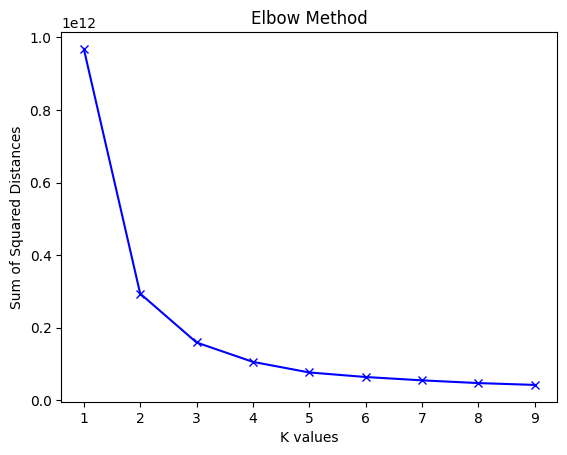

In [448]:
K = range(1,10)
sum_of_squared_distances = []

for k in K:
    model = KMeans(n_clusters=k, n_init='auto').fit(X)
    sum_of_squared_distances.append(model.inertia_)

plt.plot(K, sum_of_squared_distances, 'bx-')
plt.xlabel('K values')
plt.ylabel('Sum of Squared Distances')
plt.title('Elbow Method')
plt.show()

In [449]:
#Оскільки значення з графіка неоднозначни, натренуємо зі значеннями 2, 3, 4, 5
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, n_init='auto')
    kmeans.fit(X)

    labels = kmeans.predict(X)
    centroids = kmeans.cluster_centers_
    s = metrics.silhouette_score(X, labels, metric='euclidean')
    print(f'K = {k}, Silhouette Coefficient: {s:.3f}')

K = 2, Silhouette Coefficient: 0.574
K = 3, Silhouette Coefficient: 0.500
K = 4, Silhouette Coefficient: 0.457
K = 5, Silhouette Coefficient: 0.441


In [450]:
#Найліпша метріка сілуету на 2 кластерах, тому заново навчаємо та візуалізуємо
kmeans = KMeans(n_clusters=2, n_init='auto', random_state=42)
kmeans.fit(X)

X['Cluster'] = kmeans.labels_
fig = px.scatter_3d(X,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="Cluster",
                    title='3d візуалізація: Дохід, Покупки за каталогом, М_ясні продукти'
)
fig.show()


In [451]:
X.head()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer,Cluster
0,5524,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150,1
1,2174,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600,0
2,4141,1965,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4799,1
3,6182,1984,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4626,0
4,5324,1981,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4648,1


**Завдання 9.** Використовуючи методи `scipy` `dendrogram, linkage, fcluster`
1. Побудуйте ієрархічну агломеративну кластеризацію з `single linkage` на даних невідмасштабованих, але з прибраним викидом.
2. Візуалізуйте дендрограму. При візуалізації обовʼязково задайте параметр `truncate_mode='lastp'` - це обріже дендрограму, без цього вона буде завелика, бо у нас тут даних суттєво більше, ніж в лекції.
3. Проаналізуйте дендрограму та побудуйте варіанти плоских кластеризацій з `fcluster` на 2 і 3 кластери. Візуалізуйте результати кожної з цих кластеризацій та зробіть висновок. Чи вважаєте ви якусь з цих кластеризацій вдалою? Що спостерігаєте з цих кластеризацій?
4. Порахуйте мерику силуету для цього методу кластеризації.

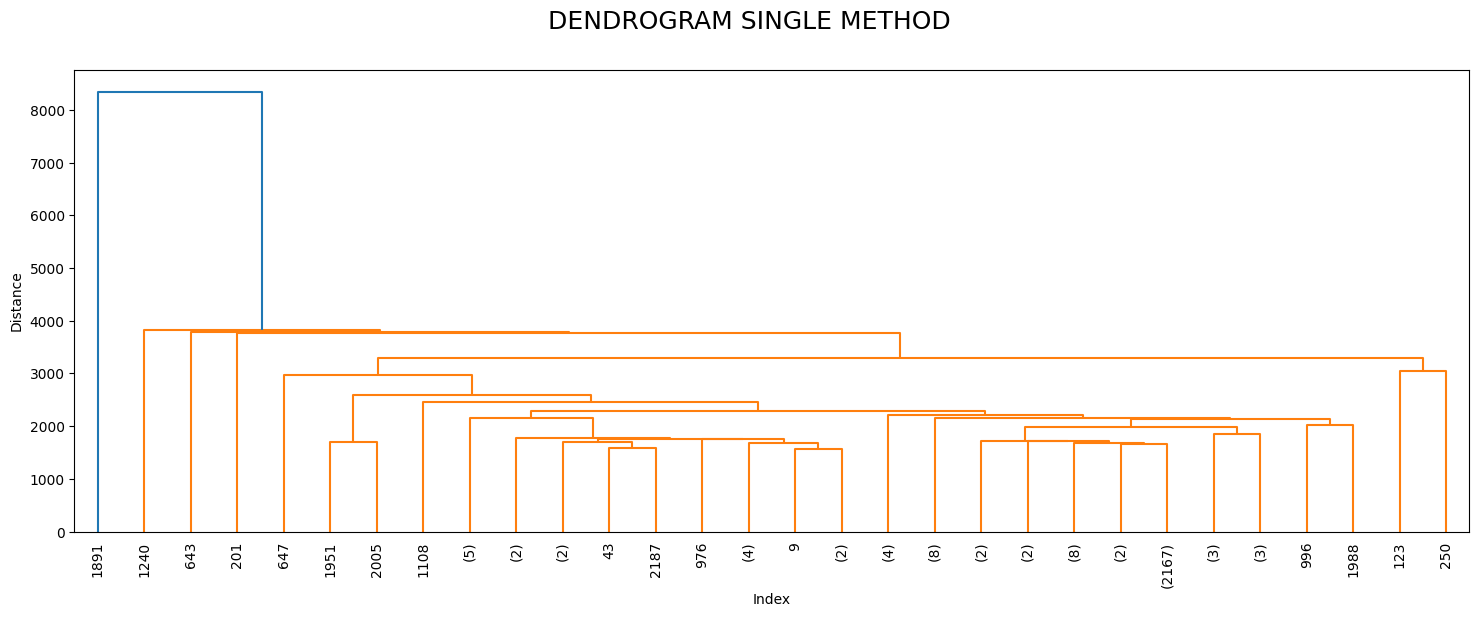

In [452]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
dist_sin = linkage(X, method="single")
plt.figure(figsize=(18,6))
dendrogram(dist_sin, leaf_rotation=90, truncate_mode='lastp')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.suptitle("DENDROGRAM SINGLE METHOD",fontsize=18)
plt.show()

Видно, що чітко виділяються два кластери.

In [453]:
X['2_clust'] = fcluster(dist_sin, 2, criterion='maxclust')
X['3_clust'] = fcluster(dist_sin, 3, criterion='maxclust')

In [454]:
X.head()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,2n Cycle,Basic,Graduation,Master,PhD,Divorced,Married,Other,Single,Together,Widow,Days_As_Customer,Cluster,2_clust,3_clust
0,5524,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5150,1,1,1
1,2174,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4600,0,1,1
2,4141,1965,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4799,1,1,1
3,6182,1984,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4626,0,1,1
4,5324,1981,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4648,1,1,1


In [455]:
fig = px.scatter_3d(X,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="2_clust",
                    title='3d візуалізація: 2_clust'
)
fig.show()

In [456]:
fig = px.scatter_3d(X,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="3_clust",
                    title='3d візуалізація: 3_clust'
)
fig.show()

In [457]:

s2 = metrics.silhouette_score(X, X['2_clust'].to_xarray(), metric='euclidean')
print(f'K = {k}, Silhouette Coefficient for 2_clust: {s2:.2f}')
s3 = metrics.silhouette_score(X, X['3_clust'].to_xarray(), metric='euclidean')
print(f'K = {k}, Silhouette Coefficient for 3_clust: {s3:.2f}')

K = 5, Silhouette Coefficient for 2_clust: 0.55
K = 5, Silhouette Coefficient for 3_clust: 0.29


**Спостереження**

Ієрархічний спосіб кластеризації не дуже вдалий для даного датасета. Я провела додаткове видалення викидів для доходу понад 117 тис. (верхня межа міжквартилного інтервалу), але це не призвело до інших результатів. В окремі кластери виділяються найвіддаленіші точки, решта маси точок як один клас.

**Завдання 10.**
1. Використайте метод кластеризації, який ми не використовували в попередніх завданнях цього ДЗ (може бути ієрархічна кластеризація з іншим способом звʼязності або інші методи sklearn).
2. Порахуйте метрику силуету і візуалізуйте результат кластеризації. Зробіть висновок про те, чи могла б ця кластеризація бути корисною?

In [458]:
# Спробуємо ward-linkage
dist_sin = linkage(X, method="ward")
X['2_clust_ward'] = fcluster(dist_sin, 2, criterion='maxclust')
fig = px.scatter_3d(X,
                    x='Income', y='NumCatalogPurchases', z='MntMeatProducts',
                    color="2_clust_ward",
                    title='3d візуалізація: 2_clust_ward'
)
fig.show()
s2_ward = metrics.silhouette_score(X, X['2_clust_ward'].to_xarray(), metric='euclidean')
print(f'Silhouette Coefficient for 2_clust_ward: {s2_ward:.3f}')



Silhouette Coefficient for 2_clust_ward: 0.569


**Спостереження**

Спосіб лінкування ward дав кращі результати за інші лінкування, але трохи меньша метрика сілуету (0.569), ніж методом k-mens (0.574). Такий спосіб може бути корисним.
В цілому не дуже зрозуміло чи кластеризувати на всіх ознаках, чи на 3-10.